# 10 — Master State-of-the-Art Dashboard

Este notebook es la **capa ejecutiva** del toolkit bibliométrico.

Los notebooks 00–09 conservan el análisis completo, las auditorías y la trazabilidad.  
Este notebook maestro lee esas salidas y presenta únicamente lo más importante para:

- comprender rápidamente el estado del arte;
- identificar tendencias dominantes y emergentes;
- explorar conceptos poco representados;
- seleccionar trabajos candidatos para lectura;
- generar figuras y texto reutilizable;
- aplicar el mismo flujo a futuros corpus de Scopus.

> **Importante:** una frecuencia baja o igual a cero dentro del corpus no demuestra por sí sola un research gap. El resultado debe confirmarse mediante búsquedas dirigidas y lectura manual.


## 0. Controles principales

Para reutilizar el notebook con otro paper, normalmente solo necesitarás:

1. reemplazar el CSV y RIS en `data/`;
2. actualizar `config.json`;
3. cambiar, si lo deseas, los parámetros de esta celda;
4. ejecutar `Run All`.

`RUN_FULL_PIPELINE = True` vuelve a ejecutar y validar los notebooks 00–09 antes de construir el dashboard.


In [1]:

from pathlib import Path
import sys
import subprocess
import json
import re
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------------
# USER CONTROLS
# ------------------------------------------------------------------
RUN_FULL_PIPELINE = False

TOP_N = 15
TOP_RELATED_WORK_PER_SECTION = 10
MIN_RELATED_WORK_CITATIONS = 0

INCLUDE_PARTIAL_YEARS_IN_TRENDS = False
SHOW_ZERO_FREQUENCY_CONCEPTS = True

EXPORT_MASTER_REPORT = True
EXPORT_MASTER_FIGURES = True

# Optional filters. Leave as None to use the whole corpus.
YEAR_FROM = None
YEAR_TO = None
DOCUMENT_TYPES = None          # Example: ["Article", "Review"]
LANGUAGES = None               # Example: ["English"]

# ------------------------------------------------------------------
# PROJECT ROOT
# ------------------------------------------------------------------
PROJECT_ROOT = None
current = Path.cwd().resolve()

for candidate in [current] + list(current.parents):
    if (candidate / "config.json").exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró config.json. Abre este notebook dentro de la carpeta "
        "Paper_Semantic_Bibliometric_Toolkit."
    )

OUTPUT_DIR = PROJECT_ROOT / "outputs"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "figures" / "master_dashboard"
VALIDATION_DIR = PROJECT_ROOT / "validation"
TOOLS_DIR = PROJECT_ROOT / "tools"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = json.loads(
    (PROJECT_ROOT / "config.json").read_text(encoding="utf-8")
)

print("Project root:", PROJECT_ROOT)
print("Query label:", CONFIG.get("query_label", "Not specified"))
print("Search date:", CONFIG.get("search_date", "Not specified"))


Project root: C:\Users\piero\Desktop\Paper_Agricultu\Paper_Semantic_Bibliometric_Toolkit_v1.0.0\Paper_Semantic_Bibliometric_Toolkit
Query label: Vision-Based Perception in Agricultural Robotics
Search date: 2026-07-12


## 1. Ejecución opcional del pipeline completo

In [2]:

if RUN_FULL_PIPELINE:
    validator = TOOLS_DIR / "validate_all_notebooks.py"

    if not validator.exists():
        raise FileNotFoundError(
            "No se encontró tools/validate_all_notebooks.py"
        )

    print("Ejecutando pipeline completo 00–09...")
    subprocess.run(
        [sys.executable, str(validator)],
        cwd=str(PROJECT_ROOT),
        check=True
    )
    print("Pipeline completado.")
else:
    print(
        "RUN_FULL_PIPELINE=False: se utilizarán las salidas existentes "
        "de los notebooks 00–09."
    )


RUN_FULL_PIPELINE=False: se utilizarán las salidas existentes de los notebooks 00–09.


## 2. Funciones de carga y compatibilidad

In [4]:

def find_existing_file(base_dir, candidate_names):
    """Return the first existing file among several compatible names."""
    for name in candidate_names:
        path = base_dir / name
        if path.exists():
            return path
    return None


def read_csv_optional(base_dir, candidate_names):
    path = find_existing_file(base_dir, candidate_names)
    if path is None:
        return pd.DataFrame(), None

    return pd.read_csv(
        path,
        encoding="utf-8-sig",
        low_memory=False
    ), path


def read_json_optional(base_dir, candidate_names):
    path = find_existing_file(base_dir, candidate_names)
    if path is None:
        return {}, None

    return json.loads(path.read_text(encoding="utf-8")), path


def detect_column(dataframe, candidates):
    if dataframe.empty:
        return None

    lower_map = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower()
        if key in lower_map:
            return lower_map[key]

    return None


def numeric_series(dataframe, column):
    if column is None or column not in dataframe.columns:
        return pd.Series(dtype=float)

    return pd.to_numeric(
        dataframe[column],
        errors="coerce"
    ).fillna(0)


def save_figure(fig, filename):
    if not EXPORT_MASTER_FIGURES:
        return

    for extension in ["png", "pdf", "svg"]:
        fig.savefig(
            FIGURES_DIR / "{}.{}".format(filename, extension),
            dpi=600,
            bbox_inches="tight"
        )


def horizontal_bar(dataframe, label_column, value_column, title, filename, top_n=15):
    if dataframe.empty:
        print("No data available for:", title)
        return

    plot_df = dataframe.copy()
    plot_df[value_column] = pd.to_numeric(
        plot_df[value_column],
        errors="coerce"
    ).fillna(0)

    plot_df = (
        plot_df
        .sort_values(value_column, ascending=False)
        .head(top_n)
        .sort_values(value_column, ascending=True)
    )

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(plot_df[label_column].astype(str), plot_df[value_column])
    ax.set_xlabel("Documents")
    ax.set_title(title)
    fig.tight_layout()

    save_figure(fig, filename)
    plt.show()


def markdown_table(dataframe, max_rows=20):
    if dataframe is None or dataframe.empty:
        return "_No data available._"

    return dataframe.head(max_rows).to_markdown(index=False)


## 3. Estado de ejecución y control de calidad

In [5]:

pipeline_log, pipeline_log_path = read_csv_optional(
    VALIDATION_DIR,
    ["pipeline_execution_log.csv"]
)

qa_table, qa_path = read_csv_optional(
    VALIDATION_DIR,
    ["final_output_quality_assurance.csv"]
)

ris_status, ris_status_path = read_csv_optional(
    OUTPUT_DIR,
    ["08_ris_status.csv"]
)

if not pipeline_log.empty:
    display(Markdown("### Pipeline execution"))
    display(pipeline_log)

    status_col = detect_column(pipeline_log, ["Status"])
    passed = int(
        pipeline_log[status_col]
        .astype(str)
        .str.upper()
        .eq("PASS")
        .sum()
    )
    total = len(pipeline_log)

    print("Pipeline:", passed, "/", total, "notebooks PASS")

if not qa_table.empty:
    display(Markdown("### Output quality assurance"))
    display(qa_table)

    qa_status_col = detect_column(qa_table, ["Status"])
    qa_passed = int(
        qa_table[qa_status_col]
        .astype(str)
        .str.upper()
        .eq("PASS")
        .sum()
    )

    print("QA outputs:", qa_passed, "/", len(qa_table), "PASS")

if not ris_status.empty:
    display(Markdown("### RIS status"))
    display(ris_status)

    exists_col = detect_column(ris_status, ["Exists"])
    if exists_col is not None:
        ris_exists = bool(ris_status.iloc[0][exists_col])
        if not ris_exists:
            display(Markdown(
                "> **Pending:** the Scopus RIS has not been detected. "
                "The dashboard works, but VOSviewer maps remain pending."
            ))


### Pipeline execution

,Notebook,Status,Seconds,Message
0,00_Setup_and_Configuration.ipynb,PASS,7.61,NaN
1,01_Corpus_Validation.ipynb,PASS,2.02,NaN
2,02_Corpus_Cleaning_and_Normalization.ipynb,PASS,4.04,NaN
3,03_Keyword_Analysis.ipynb,PASS,2.93,NaN
4,04_Scientific_Knowledge_Extraction.ipynb,PASS,3.90,NaN
5,05_Temporal_Trends_and_Emerging_Topics.ipynb,PASS,2.34,NaN
6,06_Sources_Authors_Institutions_Countries.ipynb,PASS,2.19,NaN
7,07_Citation_and_Related_Work_Selection.ipynb,PASS,2.09,NaN
8,08_VOSviewer_Preparation.ipynb,PASS,1.95,NaN
9,09_Figures_Report_and_QA.ipynb,PASS,12.62,NaN


Pipeline: 10 / 10 notebooks PASS


### Output quality assurance

,Output,Exists,Size bytes,Status
0,00_project_summary.csv,True,258,PASS
1,01_corpus_validation.json,True,3777,PASS
2,corpus_cleaned.csv,True,2781640,PASS
3,03_author_keyword_frequency.csv,True,14610,PASS
4,04_theme_statistics.csv,True,3131,PASS
5,05_documents_by_year.csv,True,509,PASS
6,06_source_statistics.csv,True,9896,PASS
7,06_author_statistics.csv,True,36344,PASS
8,06_country_statistics.csv,True,712,PASS
9,07_related_work_candidates.csv,True,186421,PASS


QA outputs: 11 / 11 PASS


### RIS status

,RIS path,Exists,Action
0,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,True,Ready


## 4. Carga de las salidas científicas

In [6]:

corpus, corpus_path = read_csv_optional(
    OUTPUT_DIR,
    ["corpus_cleaned.csv"]
)

project_summary, project_summary_path = read_csv_optional(
    OUTPUT_DIR,
    ["00_project_summary.csv"]
)

validation_json, validation_json_path = read_json_optional(
    OUTPUT_DIR,
    ["01_corpus_validation.json"]
)

documents_by_year, documents_by_year_path = read_csv_optional(
    OUTPUT_DIR,
    ["05_documents_by_year.csv"]
)

sources, sources_path = read_csv_optional(
    OUTPUT_DIR,
    ["06_source_statistics.csv", "04_top_sources.csv"]
)

authors, authors_path = read_csv_optional(
    OUTPUT_DIR,
    ["06_author_statistics.csv", "04_top_authors.csv"]
)

countries, countries_path = read_csv_optional(
    OUTPUT_DIR,
    ["06_country_statistics.csv", "04_top_countries.csv"]
)

keywords, keywords_path = read_csv_optional(
    OUTPUT_DIR,
    ["03_author_keyword_frequency.csv"]
)

themes, themes_path = read_csv_optional(
    OUTPUT_DIR,
    ["04_theme_statistics.csv", "03_theme_statistics.csv"]
)

emerging_topics, emerging_topics_path = read_csv_optional(
    OUTPUT_DIR,
    [
        "05_emerging_topics.csv",
        "05_emerging_keywords.csv",
        "05_keyword_temporal_summary.csv"
    ]
)

related_work, related_work_path = read_csv_optional(
    OUTPUT_DIR,
    ["07_related_work_candidates.csv"]
)

loaded_files = pd.DataFrame([
    {"Dataset": "Corpus", "Path": corpus_path, "Rows": len(corpus)},
    {"Dataset": "Documents by year", "Path": documents_by_year_path, "Rows": len(documents_by_year)},
    {"Dataset": "Sources", "Path": sources_path, "Rows": len(sources)},
    {"Dataset": "Authors", "Path": authors_path, "Rows": len(authors)},
    {"Dataset": "Countries", "Path": countries_path, "Rows": len(countries)},
    {"Dataset": "Keywords", "Path": keywords_path, "Rows": len(keywords)},
    {"Dataset": "Themes", "Path": themes_path, "Rows": len(themes)},
    {"Dataset": "Emerging topics", "Path": emerging_topics_path, "Rows": len(emerging_topics)},
    {"Dataset": "Related Work", "Path": related_work_path, "Rows": len(related_work)},
])

display(loaded_files)


,Dataset,Path,Rows
0,Corpus,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,272
1,Documents by year,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,27
2,Sources,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,146
3,Authors,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,1084
4,Countries,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,46
5,Keywords,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,677
6,Themes,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,103
7,Emerging topics,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,397
8,Related Work,C:\Users\piero\Desktop\Paper_Agricultu\Paper_S...,99


## 5. Filtro general del corpus

Este filtro afecta las tablas construidas directamente desde `corpus_cleaned.csv`.  
Las tablas agregadas precomputadas representan el corpus completo, salvo que vuelvas a ejecutar el pipeline con filtros incorporados.


In [7]:

filtered_corpus = corpus.copy()

if not filtered_corpus.empty:
    year_column = detect_column(filtered_corpus, ["Year"])
    document_type_column = detect_column(
        filtered_corpus,
        ["Document Type"]
    )
    language_column = detect_column(
        filtered_corpus,
        ["Language of Original Document"]
    )

    if year_column is not None:
        filtered_corpus[year_column] = pd.to_numeric(
            filtered_corpus[year_column],
            errors="coerce"
        )

        if YEAR_FROM is not None:
            filtered_corpus = filtered_corpus[
                filtered_corpus[year_column] >= YEAR_FROM
            ]

        if YEAR_TO is not None:
            filtered_corpus = filtered_corpus[
                filtered_corpus[year_column] <= YEAR_TO
            ]

    if DOCUMENT_TYPES is not None and document_type_column is not None:
        filtered_corpus = filtered_corpus[
            filtered_corpus[document_type_column].isin(DOCUMENT_TYPES)
        ]

    if LANGUAGES is not None and language_column is not None:
        filtered_corpus = filtered_corpus[
            filtered_corpus[language_column].isin(LANGUAGES)
        ]

print("Documents in complete corpus:", len(corpus))
print("Documents after dashboard filters:", len(filtered_corpus))


Documents in complete corpus: 272
Documents after dashboard filters: 272


## 6. Executive overview

In [8]:

documents_total = len(corpus)

if documents_total == 0 and validation_json:
    documents_total = int(validation_json.get("Documents", 0))

year_min = None
year_max = None

if not corpus.empty:
    year_column = detect_column(corpus, ["Year"])

    if year_column is not None:
        years = pd.to_numeric(
            corpus[year_column],
            errors="coerce"
        ).dropna()

        if not years.empty:
            year_min = int(years.min())
            year_max = int(years.max())

abstract_coverage = None
author_keyword_coverage = None
index_keyword_coverage = None
doi_coverage = None

for item in validation_json.get("Coverage", []):
    field = item.get("Field")
    value = item.get("Coverage (%)")

    if field == "Abstract":
        abstract_coverage = value
    elif field == "Author Keywords":
        author_keyword_coverage = value
    elif field == "Index Keywords":
        index_keyword_coverage = value
    elif field == "DOI":
        doi_coverage = value

overview = pd.DataFrame([
    {"Indicator": "Documents", "Value": documents_total},
    {"Indicator": "Year range", "Value": "{}–{}".format(year_min, year_max)},
    {"Indicator": "Abstract coverage (%)", "Value": abstract_coverage},
    {"Indicator": "Author keyword coverage (%)", "Value": author_keyword_coverage},
    {"Indicator": "Index keyword coverage (%)", "Value": index_keyword_coverage},
    {"Indicator": "DOI coverage (%)", "Value": doi_coverage},
])

display(overview)


,Indicator,Value
0,Documents,272
1,Year range,1993–2027
2,Abstract coverage (%),None
3,Author keyword coverage (%),None
4,Index keyword coverage (%),None
5,DOI coverage (%),None


## 7. Scientific production over time

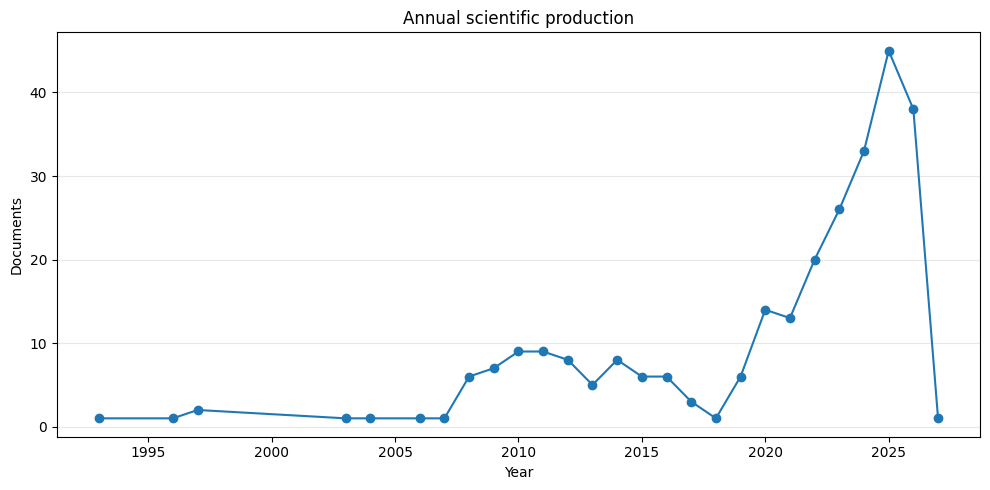

,Year,Documents,Year status
12,2013,5,complete
13,2014,8,complete
14,2015,6,complete
15,2016,6,complete
16,2017,3,complete
17,2018,1,complete
18,2019,6,complete
19,2020,14,complete
20,2021,13,complete
21,2022,20,complete


In [9]:

if not documents_by_year.empty:
    year_col = detect_column(documents_by_year, ["Year"])
    documents_col = detect_column(
        documents_by_year,
        ["Documents", "Document count"]
    )

    trend_df = documents_by_year.copy()
    trend_df[year_col] = pd.to_numeric(
        trend_df[year_col],
        errors="coerce"
    )
    trend_df[documents_col] = pd.to_numeric(
        trend_df[documents_col],
        errors="coerce"
    )

    if not INCLUDE_PARTIAL_YEARS_IN_TRENDS:
        excluded_years = set(
            CONFIG.get("exclude_partial_years_from_growth", [])
        )
        trend_df = trend_df[
            ~trend_df[year_col].isin(excluded_years)
        ]

    trend_df = trend_df.dropna().sort_values(year_col)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(
        trend_df[year_col],
        trend_df[documents_col],
        marker="o"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel("Documents")
    ax.set_title("Annual scientific production")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()

    save_figure(fig, "master_annual_scientific_production")
    plt.show()

    display(trend_df.tail(15))
else:
    print("Annual production table not found.")


## 8. Leading sources, countries, authors, and keywords

### Leading sources

,Source title normalized,Documents,Citations
0,Transactions of the Chinese Society of Agricul...,22,329
1,Computers and Electronics in Agriculture,20,2782
2,Journal of Field Robotics,11,806
3,Nongye Gongcheng Xuebao/Transactions of the Ch...,10,181
4,Agronomy,9,250
5,Agriculture (Switzerland),8,137
6,Sensors,7,50
7,Proceedings of SPIE - The International Societ...,6,22
8,IEEE Access,5,387
9,IEEE Robotics and Automation Letters,4,55


C:\Users\piero\AppData\Local\Temp\ipykernel_17996\549350595.py:91: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


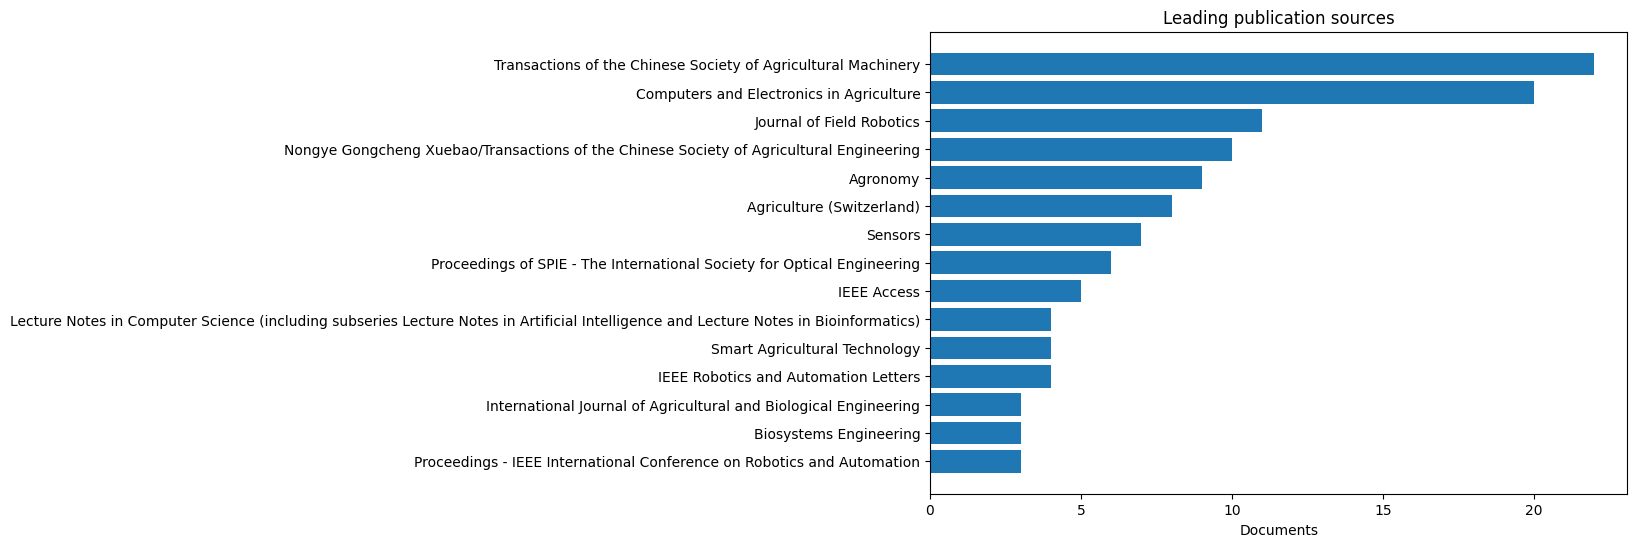

### Leading countries

,Country,Documents,Citations
0,China,156,4779
1,Japan,23,1114
2,United States,17,377
3,India,9,137
4,Australia,6,314
5,United Kingdom,6,168
6,Germany,6,107
7,Greece,6,105
8,South Korea,5,67
9,Russia,5,23


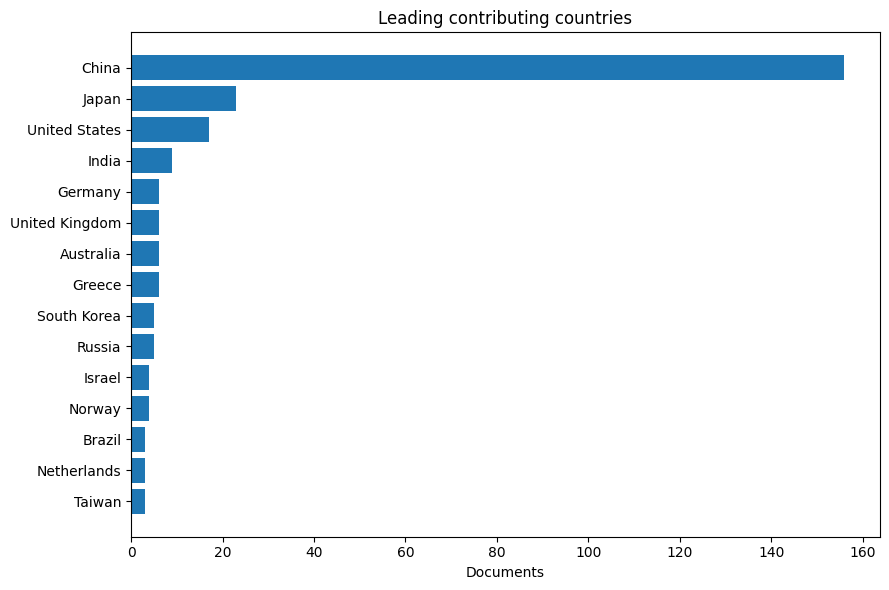

### Leading authors

,Author,Author ID,Documents,Citations
0,"Liu, Chengliang",7409795747,7,419
1,"Gong, Liang",36637488200,6,413
2,"Zou, Xiangjun",14053286400,6,297
3,"Feng, Qingchun",36598099200,6,157
4,"Yuan, Ting",57205195453,6,110
5,"Ji, Wei",55532666900,6,93
6,"Zhou, Jun",56380682100,5,263
7,"Xiong, Ya",57207216983,5,152
8,"Li, Wei",53984758300,5,77
12,"Ji, Changying",7202015303,4,95


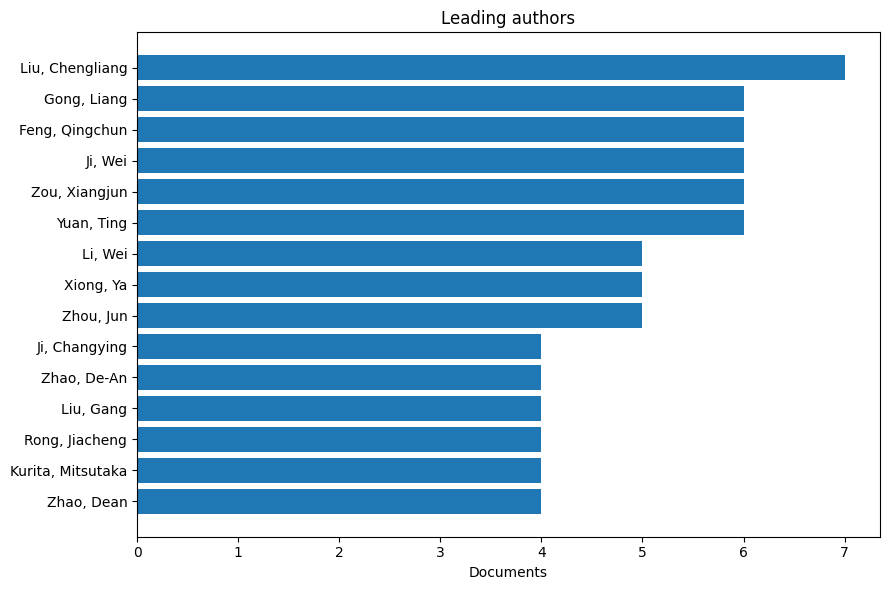

### Leading author keywords

,Keyword normalized,Documents
0,harvesting robot,53
1,computer vision,38
2,machine vision,37
3,deep learning,36
4,agricultural robot,34
5,object detection,34
6,agricultural robotics,16
7,precision agriculture,16
8,semantic segmentation,16
9,image processing,14


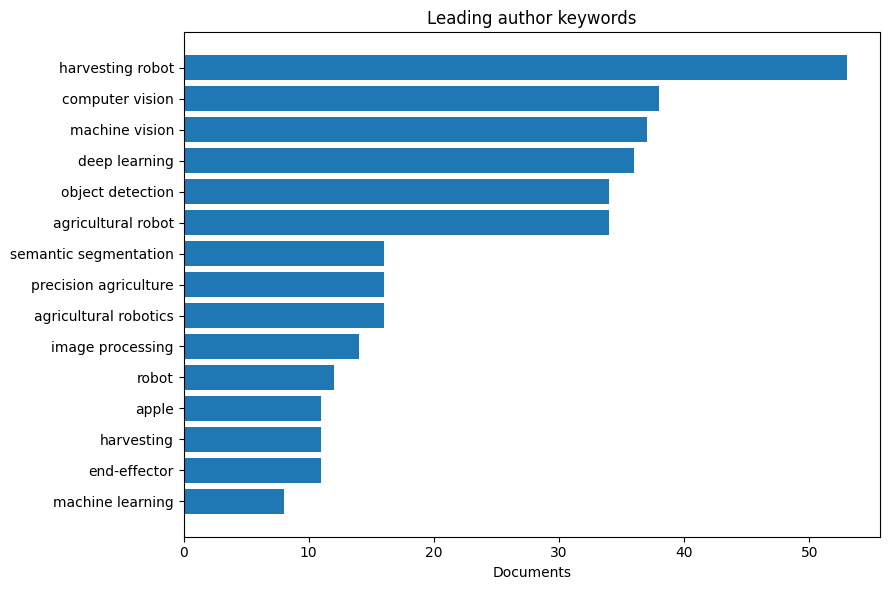

In [10]:

# SOURCES
source_label = detect_column(
    sources,
    ["Source title normalized", "Source title", "Source"]
)
source_documents = detect_column(
    sources,
    ["Documents", "Document count"]
)

if source_label and source_documents:
    display(Markdown("### Leading sources"))
    display(
        sources
        .sort_values(source_documents, ascending=False)
        .head(TOP_N)
    )
    horizontal_bar(
        sources,
        source_label,
        source_documents,
        "Leading publication sources",
        "master_leading_sources",
        TOP_N
    )

# COUNTRIES
country_label = detect_column(
    countries,
    ["Country"]
)
country_documents = detect_column(
    countries,
    ["Documents", "Document count"]
)

if country_label and country_documents:
    display(Markdown("### Leading countries"))
    display(
        countries
        .sort_values(country_documents, ascending=False)
        .head(TOP_N)
    )
    horizontal_bar(
        countries,
        country_label,
        country_documents,
        "Leading contributing countries",
        "master_leading_countries",
        TOP_N
    )

# AUTHORS
author_label = detect_column(
    authors,
    ["Author", "Author name", "Authors"]
)
author_documents = detect_column(
    authors,
    ["Documents", "Document count"]
)

if author_label and author_documents:
    display(Markdown("### Leading authors"))
    display(
        authors
        .sort_values(author_documents, ascending=False)
        .head(TOP_N)
    )
    horizontal_bar(
        authors,
        author_label,
        author_documents,
        "Leading authors",
        "master_leading_authors",
        TOP_N
    )

# KEYWORDS
keyword_label = detect_column(
    keywords,
    ["Keyword normalized", "Keyword", "Author Keyword"]
)
keyword_documents = detect_column(
    keywords,
    ["Documents", "Document count"]
)

if keyword_label and keyword_documents:
    display(Markdown("### Leading author keywords"))
    display(
        keywords
        .sort_values(keyword_documents, ascending=False)
        .head(TOP_N)
    )
    horizontal_bar(
        keywords,
        keyword_label,
        keyword_documents,
        "Leading author keywords",
        "master_leading_author_keywords",
        TOP_N
    )


## 9. Domain structure

La taxonomía resume tecnologías, sensores, tareas, robots, cultivos, entornos, métricas y conceptos semánticos.

Las categorías pueden superponerse: un mismo documento puede pertenecer a varias categorías.


Available families: Crop, Environment, Metric, Robot type, Semantic/Assistance, Sensor, Task, Technology


### Crop

,Family,Concept,Documents,Percentage
0,Crop,Tomato,41,15.07
1,Crop,Apple,35,12.87
2,Crop,Strawberry,24,8.82
3,Crop,Grape,9,3.31
4,Crop,Maize/Corn,8,2.94
5,Crop,Cucumber,6,2.21
6,Crop,Cherry,5,1.84
7,Crop,Pepper,5,1.84
8,Crop,Berry,4,1.47
9,Crop,Citrus,4,1.47


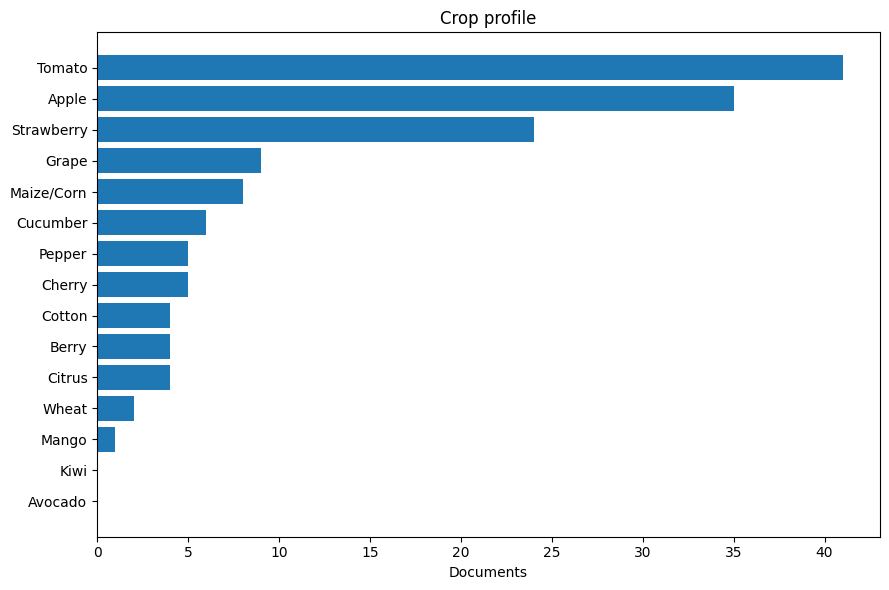

### Environment

,Family,Concept,Documents,Percentage
15,Environment,Orchard,37,13.60
16,Environment,Greenhouse,35,12.87
17,Environment,Vineyard,5,1.84
18,Environment,Open field,3,1.10
19,Environment,Row crops,2,0.74
20,Environment,Under-canopy,2,0.74
21,Environment,Protected agriculture,1,0.37
22,Environment,Indoor agriculture,0,0.00


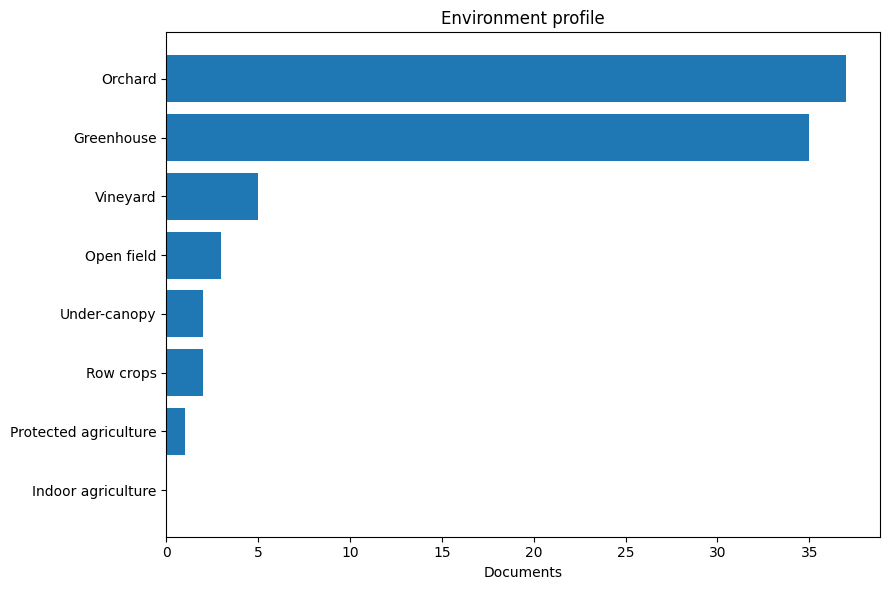

### Metric

,Family,Concept,Documents,Percentage
23,Metric,Accuracy,110,40.44
24,Metric,Precision,76,27.94
25,Metric,mAP,34,12.50
26,Metric,Recall,18,6.62
27,Metric,IoU,16,5.88
28,Metric,FPS,15,5.51
29,Metric,Inference time,7,2.57
30,Metric,F1-score,5,1.84
31,Metric,RMSE,2,0.74
32,Metric,Dice,1,0.37


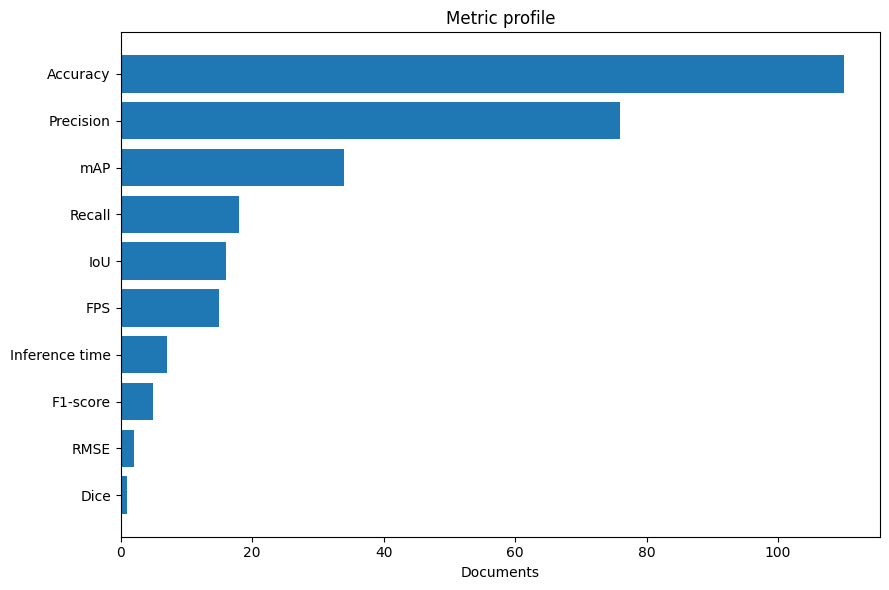

### Robot type

,Family,Concept,Documents,Percentage
33,Robot type,Harvesting robot,161,59.19
34,Robot type,Agricultural robot,140,51.47
35,Robot type,Manipulator,33,12.13
36,Robot type,Fruit-picking robot,20,7.35
37,Robot type,Mobile robot,9,3.31
38,Robot type,Orchard robot,8,2.94
39,Robot type,Greenhouse robot,4,1.47
40,Robot type,Collaborative robot,2,0.74
41,Robot type,Field robot,2,0.74


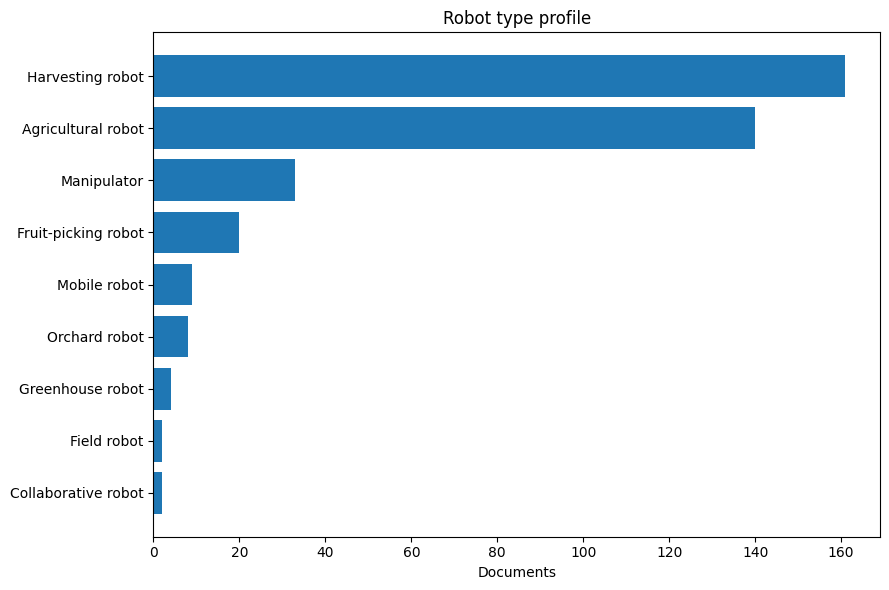

### Semantic/Assistance

,Family,Concept,Documents,Percentage
42,Semantic/Assistance,Scene understanding,3,1.10
43,Semantic/Assistance,Workload,3,1.10
44,Semantic/Assistance,Context-aware,1,0.37
45,Semantic/Assistance,Human-robot collaboration,1,0.37
46,Semantic/Assistance,Human-robot interaction,1,0.37
47,Semantic/Assistance,Scene classification,1,0.37
48,Semantic/Assistance,Semantic perception,1,0.37
49,Semantic/Assistance,Activity recognition,0,0.00
50,Semantic/Assistance,Assistance prediction,0,0.00
51,Semantic/Assistance,Human-object interaction,0,0.00


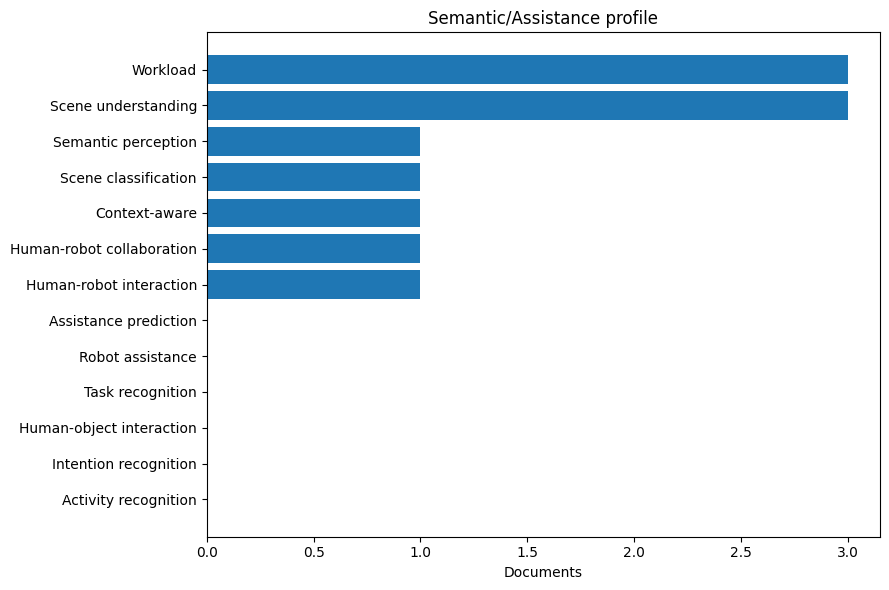

### Sensor

,Family,Concept,Documents,Percentage
55,Sensor,Camera (generic),74,27.21
56,Sensor,Stereo camera,19,6.99
57,Sensor,RGB-D camera,17,6.25
58,Sensor,LiDAR,13,4.78
59,Sensor,RGB camera,13,4.78
60,Sensor,GNSS/GPS,11,4.04
61,Sensor,Multispectral,3,1.10
62,Sensor,UAV/Drone,3,1.10
63,Sensor,IMU,2,0.74
64,Sensor,Hyperspectral,0,0.00


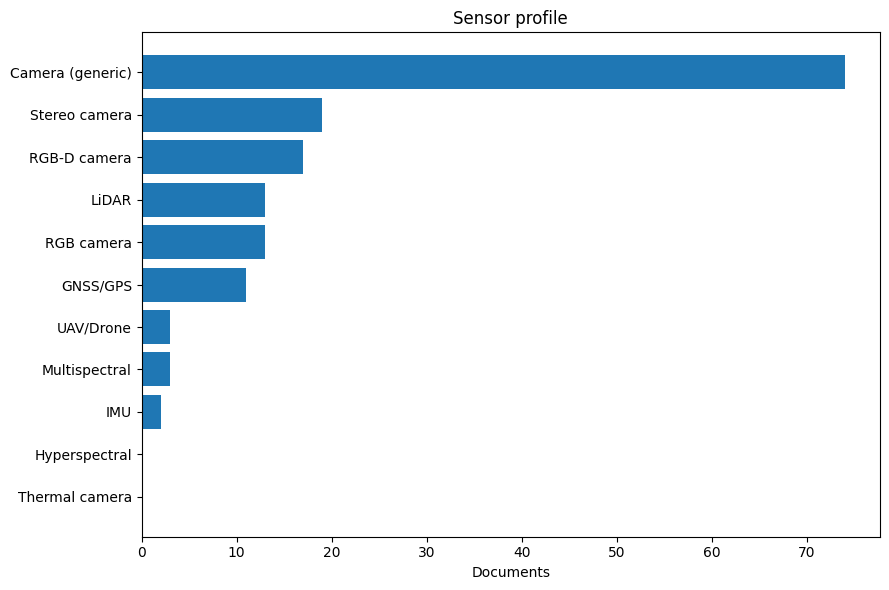

### Task

,Family,Concept,Documents,Percentage
66,Task,Harvesting,195,71.69
67,Task,Navigation,78,28.68
68,Task,Segmentation,68,25.00
69,Task,Grasping and manipulation,65,23.90
70,Task,Object detection,55,20.22
71,Task,Localization,48,17.65
72,Task,Visual servoing,30,11.03
73,Task,Classification,23,8.46
74,Task,Tracking,16,5.88
75,Task,Mapping,14,5.15


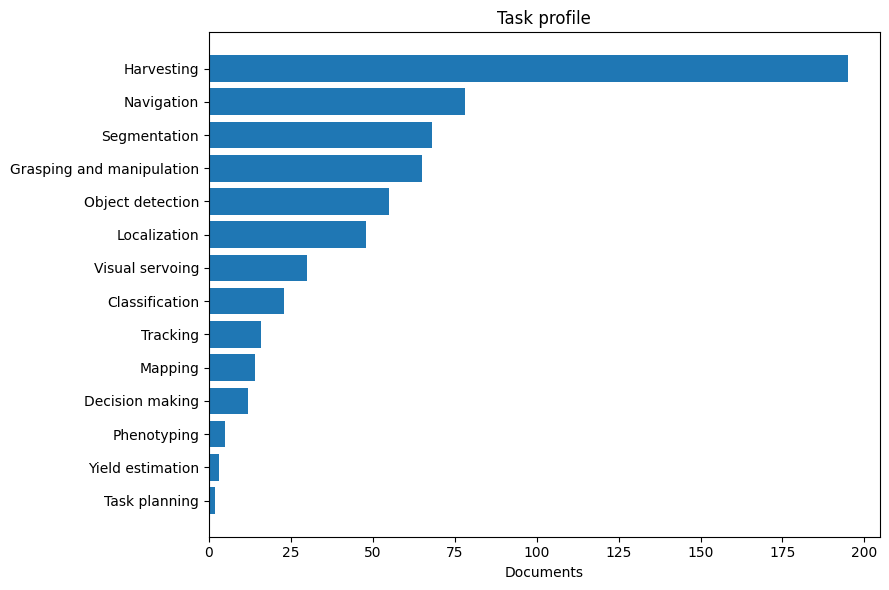

### Technology

,Family,Concept,Documents,Percentage
80,Technology,YOLO,47,17.28
81,Technology,CNN,27,9.93
82,Technology,DeepLab,9,3.31
83,Technology,MobileNet,9,3.31
84,Technology,Mask R-CNN,7,2.57
85,Technology,ResNet,7,2.57
86,Technology,Faster R-CNN,5,1.84
87,Technology,SSD,5,1.84
88,Technology,U-Net,5,1.84
89,Technology,R-CNN family,2,0.74


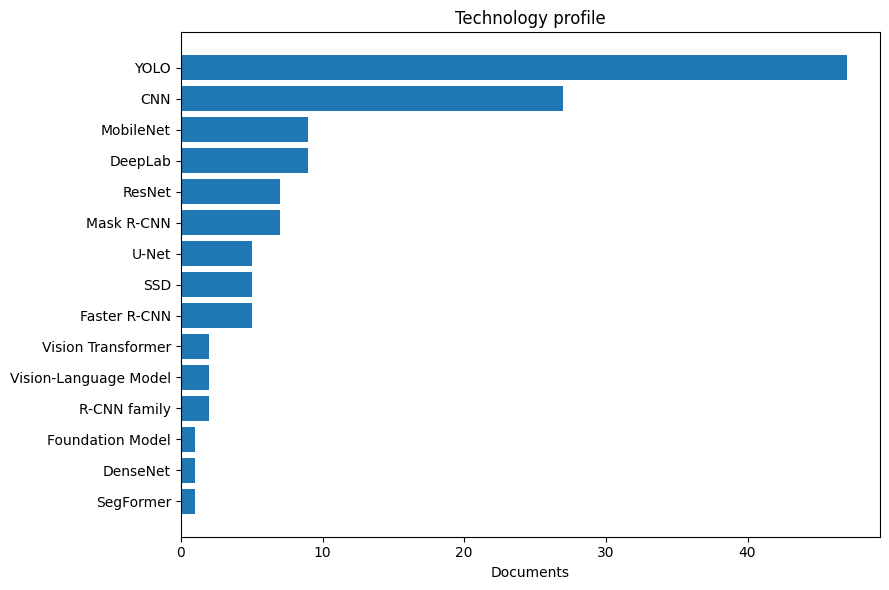

In [11]:

family_col = detect_column(themes, ["Family"])
concept_col = detect_column(themes, ["Concept"])
theme_documents_col = detect_column(
    themes,
    ["Documents", "Document count"]
)
percentage_col = detect_column(
    themes,
    ["Percentage", "Percentage (%)"]
)

if not themes.empty and family_col and concept_col and theme_documents_col:
    families = list(themes[family_col].dropna().unique())
    print("Available families:", ", ".join(map(str, families)))

    for family in families:
        family_df = themes[
            themes[family_col] == family
        ].copy()

        family_df[theme_documents_col] = pd.to_numeric(
            family_df[theme_documents_col],
            errors="coerce"
        ).fillna(0)

        if not SHOW_ZERO_FREQUENCY_CONCEPTS:
            family_df = family_df[
                family_df[theme_documents_col] > 0
            ]

        display(Markdown("### {}".format(family)))
        display(
            family_df
            .sort_values(theme_documents_col, ascending=False)
            .head(TOP_N)
        )

        horizontal_bar(
            family_df,
            concept_col,
            theme_documents_col,
            "{} profile".format(family),
            "master_domain_{}".format(
                re.sub(r"[^a-z0-9]+", "_", str(family).lower())
            ),
            TOP_N
        )
else:
    print("Domain structure table not found.")


## 10. Operational maturity versus semantic assistance

Esta comparación ayuda a visualizar si el corpus está concentrado en tareas operativas —detección, navegación, cosecha y manipulación— mientras conceptos de comprensión de escena y asistencia permanecen menos representados.


,Concept,Documents,Group
0,Harvesting,195,Operational tasks
1,Navigation,78,Operational tasks
2,Segmentation,68,Operational tasks
3,Grasping and manipulation,65,Operational tasks
4,Object detection,55,Operational tasks
5,Localization,48,Operational tasks
6,Visual servoing,30,Operational tasks
7,Classification,23,Operational tasks
8,Scene understanding,3,Semantic/assistance
9,Workload,3,Semantic/assistance


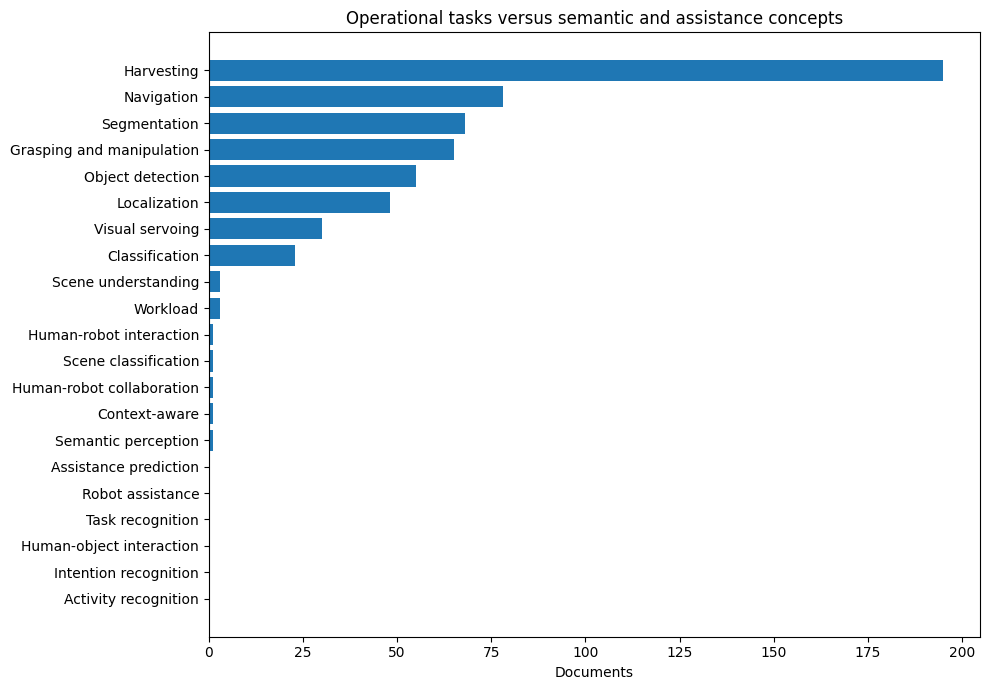

> **Interpretation rule:** low frequency is evidence of underrepresentation inside this corpus, not definitive proof that the topic is absent from the field.

In [12]:

gap_table = pd.DataFrame()

if not themes.empty and family_col and concept_col and theme_documents_col:
    semantic_mask = (
        themes[family_col]
        .astype(str)
        .str.contains("Semantic", case=False, na=False)
    )

    semantic_df = themes[semantic_mask].copy()
    semantic_df[theme_documents_col] = pd.to_numeric(
        semantic_df[theme_documents_col],
        errors="coerce"
    ).fillna(0)

    task_df = themes[
        themes[family_col].astype(str).eq("Task")
    ].copy()
    task_df[theme_documents_col] = pd.to_numeric(
        task_df[theme_documents_col],
        errors="coerce"
    ).fillna(0)

    task_top = (
        task_df
        .sort_values(theme_documents_col, ascending=False)
        .head(8)
        [[concept_col, theme_documents_col]]
        .assign(Group="Operational tasks")
    )

    semantic_all = (
        semantic_df
        .sort_values(theme_documents_col, ascending=False)
        [[concept_col, theme_documents_col]]
        .assign(Group="Semantic/assistance")
    )

    gap_table = pd.concat(
        [task_top, semantic_all],
        ignore_index=True
    )

    display(gap_table)

    plot_df = gap_table.sort_values(
        theme_documents_col,
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(
        plot_df[concept_col].astype(str),
        plot_df[theme_documents_col]
    )
    ax.set_xlabel("Documents")
    ax.set_title(
        "Operational tasks versus semantic and assistance concepts"
    )
    fig.tight_layout()

    save_figure(
        fig,
        "master_operational_vs_semantic_assistance"
    )
    plt.show()

    display(Markdown(
        "> **Interpretation rule:** low frequency is evidence of underrepresentation "
        "inside this corpus, not definitive proof that the topic is absent from the field."
    ))


## 11. Emerging topics and temporal signals

### Emerging-topic table

,Keyword normalized,Recent documents,Previous documents,Growth,Growth ratio
0,agricultural robot,17.0,2.0,15.0,6.000
1,deep learning,21.0,11.0,10.0,1.833
2,precision agriculture,12.0,3.0,9.0,3.250
3,object detection,19.0,11.0,8.0,1.667
4,machine vision,12.0,5.0,7.0,2.167
5,image processing,7.0,2.0,5.0,2.667
6,end-effector,6.0,1.0,5.0,3.500
7,computer vision,16.0,12.0,4.0,1.308
8,semantic segmentation,8.0,4.0,4.0,1.800
9,apple harvesting,4.0,0.0,4.0,5.000


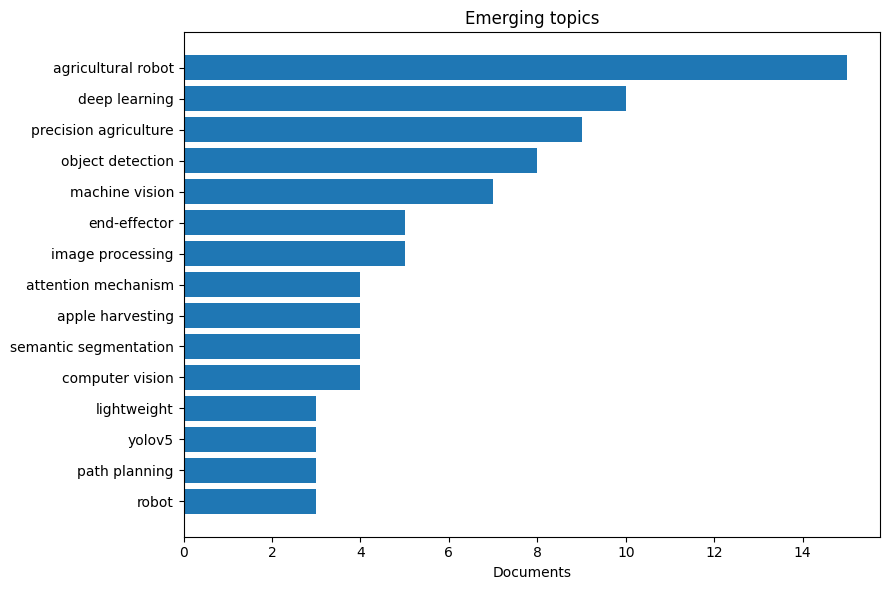

In [13]:

if not emerging_topics.empty:
    display(Markdown("### Emerging-topic table"))
    display(emerging_topics.head(30))

    emerging_label = detect_column(
        emerging_topics,
        ["Keyword normalized", "Keyword", "Concept", "Term"]
    )

    emerging_value = detect_column(
        emerging_topics,
        [
            "Growth",
            "Recent documents",
            "Total_documents",
            "Documents"
        ]
    )

    if emerging_label and emerging_value:
        horizontal_bar(
            emerging_topics,
            emerging_label,
            emerging_value,
            "Emerging topics",
            "master_emerging_topics",
            TOP_N
        )
else:
    display(Markdown(
        "_No compatible emerging-topic table was found. "
        "The annual production and domain structure remain available._"
    ))


## 12. Related Work shortlist

La tabla siguiente es una **lista priorizada para lectura**, no una selección automática para citar.

El puntaje puede combinar coincidencia temática, citas y recencia.  
Antes de incluir un trabajo en el paper debes leer al menos el título, abstract y, preferiblemente, el texto completo.


In [14]:

related_shortlist = pd.DataFrame()

if not related_work.empty:
    section_col = detect_column(
        related_work,
        ["Related Work section", "Section"]
    )
    title_col = detect_column(
        related_work,
        ["Title"]
    )
    cited_col = detect_column(
        related_work,
        ["Cited by", "Citations"]
    )
    score_col = detect_column(
        related_work,
        ["Selection score", "Score"]
    )

    related_filtered = related_work.copy()

    if cited_col is not None:
        related_filtered[cited_col] = pd.to_numeric(
            related_filtered[cited_col],
            errors="coerce"
        ).fillna(0)

        related_filtered = related_filtered[
            related_filtered[cited_col] >= MIN_RELATED_WORK_CITATIONS
        ]

    if score_col is not None:
        related_filtered[score_col] = pd.to_numeric(
            related_filtered[score_col],
            errors="coerce"
        ).fillna(0)

    if section_col is not None:
        sort_columns = [section_col]
        ascending = [True]

        if score_col is not None:
            sort_columns.append(score_col)
            ascending.append(False)
        elif cited_col is not None:
            sort_columns.append(cited_col)
            ascending.append(False)

        related_filtered = related_filtered.sort_values(
            sort_columns,
            ascending=ascending
        )

        related_shortlist = (
            related_filtered
            .groupby(section_col, group_keys=False)
            .head(TOP_RELATED_WORK_PER_SECTION)
            .reset_index(drop=True)
        )
    else:
        related_shortlist = related_filtered.head(
            TOP_RELATED_WORK_PER_SECTION
        )

    if "Manual decision" not in related_shortlist.columns:
        related_shortlist["Manual decision"] = ""

    if "Reading notes" not in related_shortlist.columns:
        related_shortlist["Reading notes"] = ""

    display(related_shortlist)

    related_shortlist.to_csv(
        OUTPUT_DIR / "master_related_work_shortlist.csv",
        index=False,
        encoding="utf-8-sig"
    )
else:
    print("Related Work candidate table not found.")


,Related Work section,Title,Year,Authors,Source title normalized,Document Type,Cited by,Citations per year,DOI,Match count,Selection score,Abstract,Manual decision,Reading notes
0,"Scene Classification, Object Detection, and Se...",Fruit detection for strawberry harvesting robo...,2019,Yu Y.; Zhang K.; Yang L.; Zhang D.,Computers and Electronics in Agriculture,Article,650,81.250,10.1016/j.compag.2019.06.001,5,41.223035,Deep learning has demonstrated excellent capab...,,
1,"Scene Classification, Object Detection, and Se...",Study of convolutional neural network-based se...,2023,Yu J.; Zhang J.; Shu A.; Chen Y.; Chen J.; Yan...,Computers and Electronics in Agriculture,Article,75,18.750,10.1016/j.compag.2023.107811,7,30.592798,Smart agricultural machinery is emerging as th...,,
2,"Scene Classification, Object Detection, and Se...",Development of a Grape Cut Point Detection Sys...,2024,Yang L.; Noguchi T.; Hoshino Y.,Sensors,Article,5,1.667,10.3390/s24248035,8,27.366156,Harvesting grapes requires a large amount of m...,,
3,"Scene Classification, Object Detection, and Se...",Object Detection and Recognition Techniques Ba...,2023,Xiao F.; Wang H.; Li Y.; Cao Y.; Lv X.; Xu G.,Agronomy,Review,88,22.000,10.3390/agronomy13030639,5,26.808981,"The accuracy, speed, and robustness of object ...",,
4,"Scene Classification, Object Detection, and Se...",Fruit Harvesting Robot Using Computer Vision,2022,Mangaonkar S.M.; Khandelwal R.; Shaikh S.; Cha...,2022 International Conference for Advancement ...,Conference paper,8,1.600,10.1109/ICONAT53423.2022.9726126,7,24.833333,Agriculture has conventionally been a labor-in...,,
5,"Scene Classification, Object Detection, and Se...",SCEA-YOLO: A General-Purpose Maturity Grading ...,2026,Li T.; Liu P.; Song D.; Zhao X.; Lyu X.; Zhang K.,Plants,Article,0,0.000,10.3390/plants15071102,7,23.000000,Accurate classification of fruit maturity is e...,,
6,"Scene Classification, Object Detection, and Se...",Automatic generation of synthetic data and obj...,2026,Ushiroji T.; Fujinaga T.,Smart Agricultural Technology,Article,0,0.000,10.1016/j.atech.2026.101947,7,23.000000,This paper presents a method for the automatic...,,
7,"Scene Classification, Object Detection, and Se...",Semantic Segmentation of Strawberry Plants Usi...,2023,Fujinaga T.; Nakanishi T.,2023 IEEE/SICE International Symposium on Syst...,Conference paper,11,2.750,10.1109/SII55687.2023.10039322,6,22.339102,This study presents a method for identifying s...,,
8,"Scene Classification, Object Detection, and Se...",Semantic segmentation-based observation pose e...,2025,Dong L.; Zhu L.; Zhao B.; Wang R.; Ni J.; Liu ...,Computers and Electronics in Agriculture,Article,8,4.000,10.1016/j.compag.2025.109895,6,21.958333,Accurate identification and localization of pe...,,
9,"Scene Classification, Object Detection, and Se...",A Real-Time Olive Fruit Detection for Harvesti...,2023,Aljaafreh A.; Elzagzoug E.Y.; Abukhait J.; Sol...,Acta Technologica Agriculturae,Article,27,6.750,10.2478/ata-2023-0017,5,21.166503,Deep neural network models have become powerfu...,,


## 13. Automatically generated interpretation

Se generan dos versiones:

- interpretación en español para comprender el panorama;
- texto en inglés como punto de partida para el paper.

El texto debe revisarse antes de publicarse.


In [15]:

def top_concepts_for_family(family_name, number=3):
    if themes.empty:
        return []

    subset = themes[
        themes[family_col].astype(str).eq(family_name)
    ].copy()

    if subset.empty:
        return []

    subset[theme_documents_col] = pd.to_numeric(
        subset[theme_documents_col],
        errors="coerce"
    ).fillna(0)

    return (
        subset
        .sort_values(theme_documents_col, ascending=False)
        .head(number)
        [[concept_col, theme_documents_col]]
        .to_dict("records")
    )


def concept_phrase(records):
    if not records:
        return "no available data"

    return ", ".join(
        "{} ({} documents)".format(
            item[concept_col],
            int(item[theme_documents_col])
        )
        for item in records
    )


top_tasks_records = top_concepts_for_family("Task", 5)
top_technology_records = top_concepts_for_family("Technology", 5)
top_crop_records = top_concepts_for_family("Crop", 3)
top_sensor_records = top_concepts_for_family("Sensor", 3)

semantic_records = []

if not themes.empty:
    semantic_subset = themes[
        themes[family_col]
        .astype(str)
        .str.contains("Semantic", case=False, na=False)
    ].copy()

    if not semantic_subset.empty:
        semantic_subset[theme_documents_col] = pd.to_numeric(
            semantic_subset[theme_documents_col],
            errors="coerce"
        ).fillna(0)

        semantic_records = (
            semantic_subset
            .sort_values(theme_documents_col, ascending=True)
            .head(6)
            [[concept_col, theme_documents_col]]
            .to_dict("records")
        )


spanish_summary = (
    "El corpus bibliográfico contiene {documents} documentos"
    "{year_text}. Las tareas más representadas son {tasks}. "
    "Las tecnologías más visibles son {technologies}. "
    "Los cultivos con mayor presencia son {crops}, mientras los sensores "
    "más mencionados son {sensors}. En contraste, los conceptos semánticos "
    "y de asistencia menos representados incluyen {semantic}. "
    "Este contraste sugiere una literatura concentrada principalmente en "
    "percepción orientada a tareas operativas. Sin embargo, la baja frecuencia "
    "de un concepto dentro del corpus debe confirmarse mediante búsquedas "
    "específicas y lectura manual antes de formular un research gap."
).format(
    documents=documents_total,
    year_text=(
        " publicados entre {} y {}".format(year_min, year_max)
        if year_min is not None and year_max is not None
        else ""
    ),
    tasks=concept_phrase(top_tasks_records),
    technologies=concept_phrase(top_technology_records),
    crops=concept_phrase(top_crop_records),
    sensors=concept_phrase(top_sensor_records),
    semantic=concept_phrase(semantic_records),
)


english_summary = (
    "The bibliographic corpus comprises {documents} documents"
    "{year_text}. The most represented tasks are {tasks}, whereas the most "
    "visible technologies are {technologies}. The leading crop domains are "
    "{crops}, and the most frequently reported sensing modalities are "
    "{sensors}. In contrast, the least represented semantic and assistance-related "
    "concepts include {semantic}. This distribution indicates that the corpus is "
    "primarily concentrated on perception for operational agricultural tasks. "
    "Nevertheless, low frequency within the corpus should be triangulated through "
    "targeted searches and manual reading before it is formulated as a research gap."
).format(
    documents=documents_total,
    year_text=(
        " published between {} and {}".format(year_min, year_max)
        if year_min is not None and year_max is not None
        else ""
    ),
    tasks=concept_phrase(top_tasks_records),
    technologies=concept_phrase(top_technology_records),
    crops=concept_phrase(top_crop_records),
    sensors=concept_phrase(top_sensor_records),
    semantic=concept_phrase(semantic_records),
)

display(Markdown("### Interpretación en español\n\n" + spanish_summary))
display(Markdown("### Paper-ready starting paragraph\n\n" + english_summary))


### Interpretación en español

El corpus bibliográfico contiene 272 documentos publicados entre 1993 y 2027. Las tareas más representadas son Harvesting (195 documents), Navigation (78 documents), Segmentation (68 documents), Grasping and manipulation (65 documents), Object detection (55 documents). Las tecnologías más visibles son YOLO (47 documents), CNN (27 documents), DeepLab (9 documents), MobileNet (9 documents), Mask R-CNN (7 documents). Los cultivos con mayor presencia son Tomato (41 documents), Apple (35 documents), Strawberry (24 documents), mientras los sensores más mencionados son Camera (generic) (74 documents), Stereo camera (19 documents), RGB-D camera (17 documents). En contraste, los conceptos semánticos y de asistencia menos representados incluyen Activity recognition (0 documents), Intention recognition (0 documents), Human-object interaction (0 documents), Task recognition (0 documents), Robot assistance (0 documents), Assistance prediction (0 documents). Este contraste sugiere una literatura concentrada principalmente en percepción orientada a tareas operativas. Sin embargo, la baja frecuencia de un concepto dentro del corpus debe confirmarse mediante búsquedas específicas y lectura manual antes de formular un research gap.

### Paper-ready starting paragraph

The bibliographic corpus comprises 272 documents published between 1993 and 2027. The most represented tasks are Harvesting (195 documents), Navigation (78 documents), Segmentation (68 documents), Grasping and manipulation (65 documents), Object detection (55 documents), whereas the most visible technologies are YOLO (47 documents), CNN (27 documents), DeepLab (9 documents), MobileNet (9 documents), Mask R-CNN (7 documents). The leading crop domains are Tomato (41 documents), Apple (35 documents), Strawberry (24 documents), and the most frequently reported sensing modalities are Camera (generic) (74 documents), Stereo camera (19 documents), RGB-D camera (17 documents). In contrast, the least represented semantic and assistance-related concepts include Activity recognition (0 documents), Intention recognition (0 documents), Human-object interaction (0 documents), Task recognition (0 documents), Robot assistance (0 documents), Assistance prediction (0 documents). This distribution indicates that the corpus is primarily concentrated on perception for operational agricultural tasks. Nevertheless, low frequency within the corpus should be triangulated through targeted searches and manual reading before it is formulated as a research gap.

## 14. Export master report

In [16]:

if EXPORT_MASTER_REPORT:
    report_lines = [
        "# Master State-of-the-Art Dashboard",
        "",
        "## Search metadata",
        "",
        "- Project: {}".format(CONFIG.get("project_name", "")),
        "- Query label: {}".format(CONFIG.get("query_label", "")),
        "- Search date: {}".format(CONFIG.get("search_date", "")),
        "- Documents: {}".format(documents_total),
        "",
        "## Executive overview",
        "",
        markdown_table(overview, 20),
        "",
        "## Leading sources",
        "",
        markdown_table(
            sources.sort_values(
                source_documents,
                ascending=False
            ).head(TOP_N)
            if source_documents else pd.DataFrame(),
            TOP_N
        ),
        "",
        "## Leading countries",
        "",
        markdown_table(
            countries.sort_values(
                country_documents,
                ascending=False
            ).head(TOP_N)
            if country_documents else pd.DataFrame(),
            TOP_N
        ),
        "",
        "## Leading authors",
        "",
        markdown_table(
            authors.sort_values(
                author_documents,
                ascending=False
            ).head(TOP_N)
            if author_documents else pd.DataFrame(),
            TOP_N
        ),
        "",
        "## Leading author keywords",
        "",
        markdown_table(
            keywords.sort_values(
                keyword_documents,
                ascending=False
            ).head(TOP_N)
            if keyword_documents else pd.DataFrame(),
            TOP_N
        ),
        "",
        "## Domain structure",
        "",
        markdown_table(themes, 200),
        "",
        "## Related Work shortlist",
        "",
        markdown_table(related_shortlist, 100),
        "",
        "## Interpretation in Spanish",
        "",
        spanish_summary,
        "",
        "## Paper-ready starting paragraph",
        "",
        english_summary,
        "",
        "## Research gap caution",
        "",
        "Low or zero frequency within the corpus is exploratory evidence. "
        "It must be triangulated with targeted searches and manual reading.",
    ]

    master_report_path = (
        REPORTS_DIR / "master_state_of_the_art_dashboard.md"
    )

    master_report_path.write_text(
        "\n".join(report_lines),
        encoding="utf-8"
    )

    print("Master report:", master_report_path)
    print("Master figures:", FIGURES_DIR)
    print(
        "Related Work shortlist:",
        OUTPUT_DIR / "master_related_work_shortlist.csv"
    )


Master report: C:\Users\piero\Desktop\Paper_Agricultu\Paper_Semantic_Bibliometric_Toolkit_v1.0.0\Paper_Semantic_Bibliometric_Toolkit\reports\master_state_of_the_art_dashboard.md
Master figures: C:\Users\piero\Desktop\Paper_Agricultu\Paper_Semantic_Bibliometric_Toolkit_v1.0.0\Paper_Semantic_Bibliometric_Toolkit\figures\master_dashboard
Related Work shortlist: C:\Users\piero\Desktop\Paper_Agricultu\Paper_Semantic_Bibliometric_Toolkit_v1.0.0\Paper_Semantic_Bibliometric_Toolkit\outputs\master_related_work_shortlist.csv


# How to use this notebook for another paper

1. Export the complete Scopus CSV and RIS.
2. Replace the files inside `data/`.
3. Update `config.json`.
4. Set `RUN_FULL_PIPELINE = True`.
5. Execute `Run All`.
6. Review the executive dashboard.
7. Inspect the Related Work shortlist manually.
8. Confirm low-frequency concepts with targeted searches.
9. Use the exported Markdown report and SVG/PDF figures as the starting point for the paper.

## Division of responsibilities

- **Notebooks 00–09:** complete scientific backend and audit trail.
- **Notebook 10:** filtered dashboard for interpretation and writing.
- **VOSviewer:** network visualization using the RIS and audited thesaurus.
